# Expected goals on an NHL rink

A shot from the slot goes in far more often than one from the point. Expected goals (xG) puts a number on that:
the chance an average shooter scores from where, and how, a shot was taken. This recipe maps the 2025-26 NHL
regular season onto sportypy's rink with three SportsDataverse packages:

- [sportsdataverse-py](https://py.sportsdataverse.org) loads fastRhockey's play-by-play, whose `xg` column is
  fastRhockey's expected goals model,
- sportypy draws the rink and bins the shots with `heatmap`,
- [sdvplot](https://sdvplot.sportsdataverse.org) supplies team colors and logos.

To run it yourself: `pip install sportypy sportsdataverse "sdvplot[surfaces]"`, or from a clone of the repository, `uv run --group cookbook jupyter lab`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import sportsdataverse.nhl as nhl
from matplotlib.colors import TwoSlopeNorm

import sdvplot
from sportypy.surfaces.hockey import NHLRink

# print tables as markdown, so the docs site shows them as tables
pl.Config.set_tbl_formatting("ASCII_MARKDOWN")
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)
SEASON = 2026  # this loader names a season by the year it ends: 2026 is 2025-26

## 1. Every unblocked shot, at one net

fastRhockey's `x_fixed` and `y_fixed` are in feet on the NHL rink's frame, the one sportypy draws, with the origin
at center ice. Shots on goal, misses and goals are the unblocked attempts (a blocked shot is recorded where it was
blocked, not where it was taken). Empty-net goals are left out: they say nothing about shooting. Mirroring the
shots at the left net (flipping both signs) puts every attempt at the right one.

In [2]:
pbp = nhl.load_nhl_pbp_lite(seasons=[SEASON])
shots = (
    pbp.filter(
        pl.col("event_type").is_in(["SHOT", "MISSED_SHOT", "GOAL"])
        & (pl.col("season_type") == "R")
        & ~pl.col("empty_net")
        & pl.col("xg").is_not_null()
    )
    .with_columns(
        x=pl.col("x_fixed").abs(),
        y=pl.when(pl.col("x_fixed") < 0).then(-pl.col("y_fixed")).otherwise(pl.col("y_fixed")),
        goal=pl.col("event_type") == "GOAL",
    )
    .filter(pl.col("x") > 25)  # the offensive zone (the blue line is 25 ft from center)
)
games = pbp.filter(pl.col("season_type") == "R")["game_id"].n_unique()
print(f"{shots.height:,} unblocked shots and {shots['goal'].sum():,} goals in {games:,} games")

106,733 unblocked shots and 7,390 goals in 1,312 games


## 2. Where shots come from, and where goals come from

Two views of the same shots on the attacking half (`display_range="offense"`). On the left, `heatmap` counts the
attempts in 3-foot squares. On the right, `statistic="mean"` with `values=goal` turns each square into a shooting
percentage, with squares of fewer than 25 attempts left blank. Shots come from everywhere in the zone; goals come
from the slot and the crease.

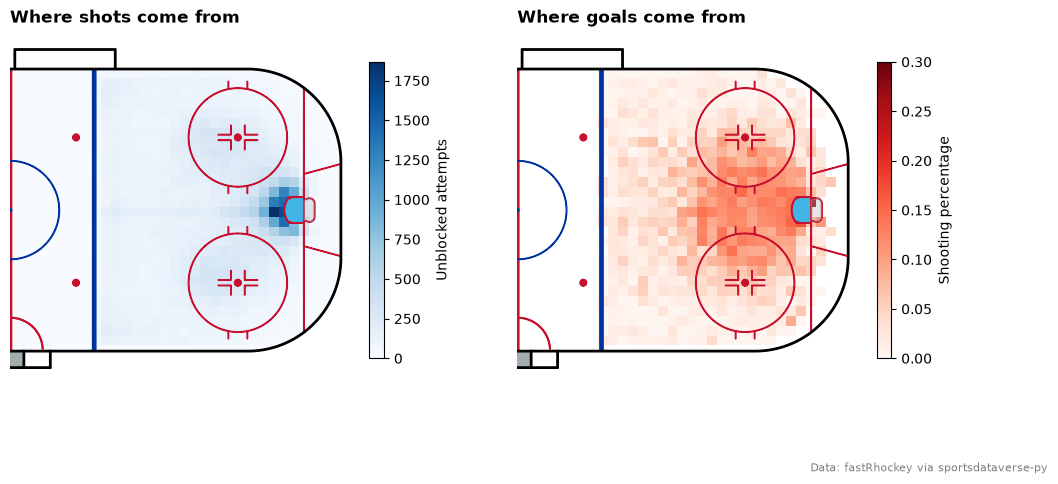

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
rink = NHLRink()

rink.draw(ax=axes[0], display_range="offense")
counts = rink.heatmap(shots["x"], shots["y"], binsize=3, cmap="Blues", ax=axes[0])
fig.colorbar(counts, ax=axes[0], shrink=0.7, pad=0.02, label="Unblocked attempts")
axes[0].set_title("Where shots come from", loc="left", fontweight="bold")

rink.draw(ax=axes[1], display_range="offense")
rate = rink.heatmap(shots["x"], shots["y"], values=shots["goal"].cast(pl.Float64), binsize=3,
                    statistic=lambda g: g.mean() if len(g) >= 25 else np.nan,
                    cmap="Reds", vmin=0, vmax=0.3, ax=axes[1])
fig.colorbar(rate, ax=axes[1], shrink=0.7, pad=0.02, label="Shooting percentage")
axes[1].set_title("Where goals come from", loc="left", fontweight="bold")
fig.text(0.99, 0.02, "Data: fastRhockey via sportsdataverse-py", ha="right", fontsize=8, color="grey")
plt.show()

## 3. Is the expected goals model calibrated?

A good xG model is honest: of the shots it gives a 10% chance, about 10% should go in. Group the shots by their
`xg` into ten equal-sized deciles and compare the average expected goal with the share that actually scored.

In [4]:
calibration = (
    shots.with_columns(decile=(pl.col("xg").rank("ordinal") * 10 / pl.len()).ceil().cast(pl.Int8))
    .group_by("decile")
    .agg(shots=pl.len(), expected=pl.col("xg").mean(), actual=pl.col("goal").mean())
    .sort("decile")
)
with pl.Config(float_precision=3):
    print(calibration)
print(f"Season: {shots['xg'].sum():,.0f} expected goals, {shots['goal'].sum():,} scored")

| decile | shots | expected | actual |
|--------|-------|----------|--------|
| 1      | 10673 | 0.007    | 0.007  |
| 2      | 10673 | 0.015    | 0.012  |
| 3      | 10673 | 0.024    | 0.017  |
| 4      | 10674 | 0.036    | 0.027  |
| 5      | 10673 | 0.049    | 0.038  |
| 6      | 10673 | 0.064    | 0.053  |
| 7      | 10674 | 0.084    | 0.077  |
| 8      | 10673 | 0.109    | 0.101  |
| 9      | 10673 | 0.147    | 0.137  |
| 10     | 10674 | 0.237    | 0.224  |
Season: 8,243 expected goals, 7,390 scored


Every decile scores more often than the one before it, so the model ranks shots well. But almost every decile comes
in under its expected rate: over 2025-26 the model ran about 10% high, 8,243 expected goals for 7,390 scored. The
goals above expected in section 5 are measured against it, so a league-average finisher sits a little below zero.

## 4. One team's shot profile against the league

Which spots does a team shoot from more often than the league? `heatmap` sums its `values`, so one call can take
the difference: give each of the team's shots `+1 / its games` and each league shot `-1 / every team's games`,
and each square shows how many more (red) or fewer (blue) attempts per game the team takes there than an average
team. The team is the one with the most expected goals, its rink's boards painted in its sdvplot color.

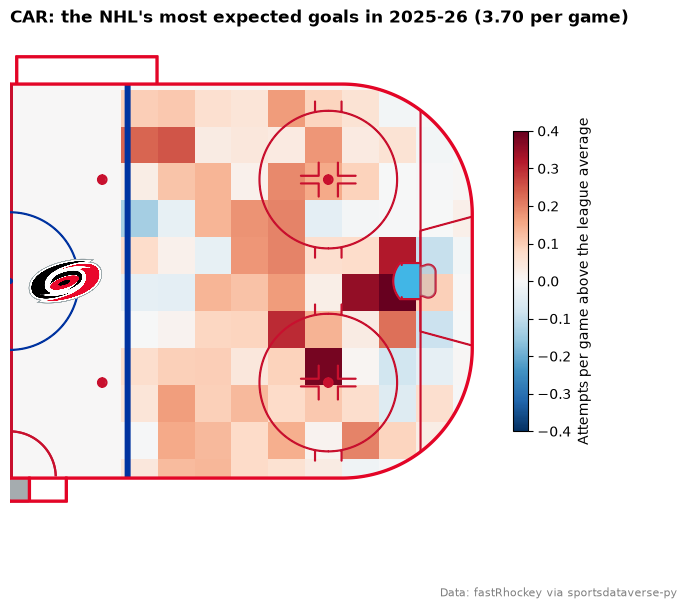

In [5]:
team_xg = shots.group_by("event_team_abbr").agg(xg=pl.col("xg").sum()).sort("xg", descending=True)
team = team_xg["event_team_abbr"][0]
team_games = pbp.filter(
    (pl.col("season_type") == "R") & ((pl.col("home_abbr") == team) | (pl.col("away_abbr") == team))
)["game_id"].n_unique()

mine = shots.filter(pl.col("event_team_abbr") == team)
x = pl.concat([mine["x"], shots["x"]])
y = pl.concat([mine["y"], shots["y"]])
weights = np.concatenate([np.full(mine.height, 1 / team_games), np.full(shots.height, -1 / (2 * games))])

primary = sdvplot.team_colors("nhl", team)
rink = NHLRink(color_updates={"boards": primary})
fig, ax = plt.subplots(figsize=(8, 6.5))
rink.draw(ax=ax, display_range="offense")
diff = rink.heatmap(x, y, values=weights, binsize=8, cmap="RdBu_r", norm=TwoSlopeNorm(0, -0.4, 0.4), ax=ax)
fig.colorbar(diff, ax=ax, shrink=0.6, pad=0.02, label="Attempts per game above the league average")
sdvplot.add_logos(ax, [12], [0], [team], league="nhl", height=0.16, zorder=30)
ax.set_title(f"{team}: the NHL's most expected goals in 2025-26 ({team_xg['xg'][0] / team_games:.2f} per game)",
             loc="left", fontweight="bold")
fig.text(0.99, 0.01, "Data: fastRhockey via sportsdataverse-py", ha="right", fontsize=8, color="grey")
plt.show()

## 5. The season's best finisher

Goals above expected is a player's goals minus the expected goals of their shots: how many more they scored than
an average shooter would have from the same chances. The leaders, with at least 100 unblocked shots:

In [6]:
finishers = (
    shots.group_by("event_player_1_name", "event_team_abbr")
    .agg(shots=pl.len(), goals=pl.col("goal").sum(), xg=pl.col("xg").sum())
    .filter(pl.col("shots") >= 100)
    .with_columns(above=pl.col("goals") - pl.col("xg"))
    .sort("above", descending=True)
)
with pl.Config(float_precision=1):
    print(finishers.head(8))

| event_player_1_name | event_team_abbr | shots | goals | xg   | above |
|---------------------|-----------------|-------|-------|------|-------|
| Anthony Mantha      | PIT             | 202   | 32    | 18.1 | 13.9  |
| Morgan Geekie       | BOS             | 262   | 38    | 24.7 | 13.3  |
| Filip Forsberg      | NSH             | 373   | 37    | 26.5 | 10.5  |
| Cole Caufield       | MTL             | 367   | 50    | 40.2 | 9.8   |
| Sidney Crosby       | PIT             | 220   | 28    | 20.0 | 8.0   |
| Wyatt Johnston      | DAL             | 292   | 44    | 36.1 | 7.9   |
| Adrian Kempe        | LAK             | 305   | 34    | 26.2 | 7.8   |
| Pavel Zacha         | BOS             | 191   | 28    | 20.2 | 7.8   |


His shots, each sized by its expected goal and the goals filled in his team's primary color:

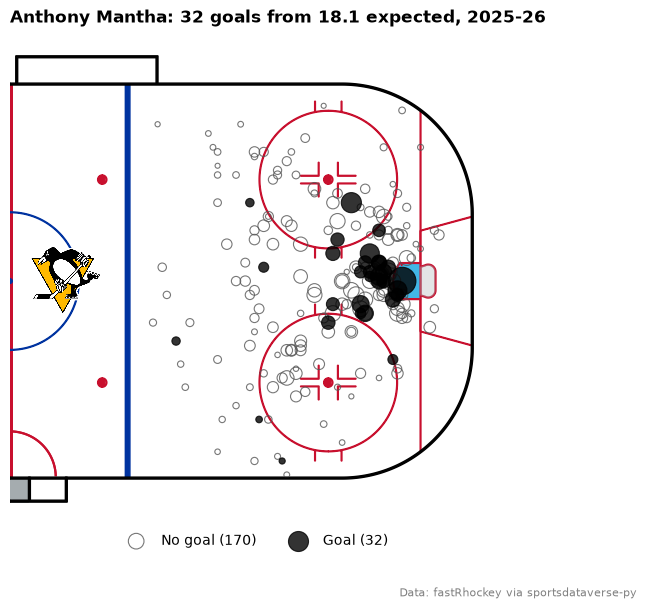

In [7]:
top = finishers.row(0, named=True)
his = shots.filter(pl.col("event_player_1_name") == top["event_player_1_name"])
color = sdvplot.team_colors("nhl", top["event_team_abbr"])

rink = NHLRink()
fig, ax = plt.subplots(figsize=(8, 6.5))
rink.draw(ax=ax, display_range="offense")
for scored, face, label in ((False, "none", "No goal"), (True, color, "Goal")):
    group = his.filter(pl.col("goal") == scored)
    rink.scatter(group["x"], group["y"], s=group["xg"] * 600 + 10, facecolors=face, edgecolors=color if scored else "#555555",
                 linewidths=0.8, alpha=0.8, label=f"{label} ({group.height})", ax=ax)
sdvplot.add_logos(ax, [12], [0], [top["event_team_abbr"]], league="nhl", height=0.16, zorder=30)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncols=2, frameon=False)
ax.set_title(f"{top['event_player_1_name']}: {top['goals']} goals from {top['xg']:.1f} expected, 2025-26",
             loc="left", fontweight="bold")
fig.text(0.99, 0.01, "Data: fastRhockey via sportsdataverse-py", ha="right", fontsize=8, color="grey")
plt.show()

## Where to go next

- The [`NHLRink` reference](https://sportypy.sportsdataverse.org/docs/reference/surfaces/hockey) lists every feature `color_updates` can repaint, and the
  [plotting reference](https://sportypy.sportsdataverse.org/docs/reference/plotting) every option of `heatmap`, `hexbin`, `contour` and `scatter`.
- sportypy draws the other leagues' rinks too (`AHLRink`, `PHFRink`, `IIHFRink`, `NCAARink` and more); their frames
  match, so the recipe needs only a different rink and data source.
- sdvplot's [surfaces and shot charts cookbook](https://sdvplot.sportsdataverse.org/docs/cookbooks/surfaces-and-shot-charts)
  draws a single player's goals on a team-colored rink in one call.